# Домашнее задание. Занятие 11. Мидтерм, этап 1: от сырого файла к чистой таблице

**DataGroup. Курс AI Engineering. Неделя 6**

Это тетрадь вашего мидтерм-проекта. На этапе 1 (домашка занятия 11) вы заполняете разделы 0-9: выбираете датасет и доводите его до чистой таблицы с EDA. На этапе 2 (домашка занятия 12, сам мидтерм) продолжаете **эту же тетрадь**, разделы 10-16: признаки, утечка, baseline и README. Полное ТЗ с критериями и списком датасетов в файле `Midterm_TZ.md`.

**Как работать с тетрадью**

1. Откройте её в Google Colab: «Файл», затем «Загрузить блокнот». Сразу переименуйте в `project.ipynb`: под этим именем она будет лежать в репозитории.
2. **Первой запустите ячейку «Помощники»** ниже. Если перезапустили среду, запустите её снова.
3. Идите по разделам сверху вниз. В каждом разделе есть **«Что сделать»**, ссылка на часть тетради практики занятия 11, где это показано на отелях, пустые ячейки для кода и ячейка **«Вывод»**: её заполняете своими словами.
4. Каждое решение про данные записывайте в журнал: `log("шаг", "что решили", len(df))`.
5. В конце этапа запустите самопроверку (раздел 9), потом «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь должна пройти без ошибок.
6. Загрузите тетрадь и файлы в публичный репозиторий на GitHub и сдайте **ссылку на репозиторий** в LMS. Как загрузить, в разделе 9 и в ТЗ.

**Баллы этапа 1: 100.**

| раздел | баллы |
|---|---|
| 0-1. Карточка проекта и первый взгляд | 10 |
| 2-3. Дубли и невозможные значения | 15 |
| 4. Пропуски | 20 |
| 5-6. Типы, даты и выбросы | 15 |
| 7. EDA: 5 графиков с выводами | 20 |
| 8. Функция `clean`, сторожа, журнал, чистый CSV | 10 |
| 9. Репозиторий: публичный, тетрадь с выводами | 10 |

**Данные.** Один датасет из списка в ТЗ или свой, согласованный в чате группы. Вот список коротко, ссылки и подробности в ТЗ:

| датасет | задача | уровень |
|---|---|---|
| клиенты телеком-компании (Telco) | классификация: уйдёт ли клиент | базовый |
| поездки на такси в Нью-Йорке | регрессия: чаевые или стоимость | базовый |
| рейтинги шоколада | регрессия: оценка плитки | базовый |
| банк: телемаркетинг вкладов | классификация: откроет ли вклад | средний |
| восхождения в Гималаях | классификация: дойдёт ли до вершины | средний |
| Airbnb в Нью-Йорке | регрессия: цена ночи | средний |
| песни Spotify | регрессия: популярность трека | средний |
| мебель IKEA | регрессия: цена | средний |
| оценки кофе | регрессия: итоговая оценка | продвинутый |
| дома в Эймсе | регрессия: цена дома | продвинутый |

**Как устроено.** Проверки с баллами здесь нет: работу проверяет преподаватель по критериям из ТЗ. Решения принимаете вы, и главное в каждом разделе не код, а **вывод**: что вы увидели и почему решили именно так. Короткий честный вывод лучше длинного пересказа кода.

**Чем пользоваться.** Помощники ниже: `load_csv`, `passport`, `log` и `show_journal`, `target_plot`, `selfcheck`. Всё остальное из тетради практики занятия 11: её функции можно копировать и менять под свои данные.

**Если застряли.** Каждый раздел ссылается на часть тетради практики, где то же самое сделано на отелях. Задайте вопрос в чате группы, не дожидаясь срока. И ставьте `print` после каждого шага: почти всегда окажется, что в таблице лежит не то, что вы думали.

---
## Помощники

Запустите эту ячейку первой. Она подключает библиотеки и создаёт пять функций для проекта.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("project_data")
DATA.mkdir(exist_ok=True)
TEAL, ORANGE, RED, NAVY, GRAY = "#278071", "#E0843B", "#B0413E", "#13293E", "#8A94A0"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)


def load_csv(url, name="raw", **options):
    """Скачать CSV по ссылке один раз в папку project_data, дальше читать с диска."""
    path = DATA / f"{name}.csv"
    if not path.exists():
        urlretrieve(url, path)
    return pd.read_csv(path, **options)


def passport(table):
    """Паспорт данных: одна строка на столбец, тип, пропуски, разных значений, пример."""
    return pd.DataFrame({
        "тип": table.dtypes.astype(str),
        "пропусков": table.isna().sum(),
        "доля, %": (table.isna().mean() * 100).round(1),
        "разных": table.nunique(),
        "пример": table.iloc[0],
    })


journal = {}


def log(step, decision, rows):
    """Записать решение в журнал. Повторный запуск с тем же шагом перезаписывает запись."""
    journal[step] = {"решение": decision, "строк": rows}


def show_journal():
    """Журнал решений таблицей."""
    return pd.DataFrame(journal).T


def target_plot(table, groups, target, title, xlabel):
    """Цель по группам. Цель 0 и 1: доля единиц в процентах. Цель число: медиана."""
    is_class = set(table[target].dropna().unique()) <= {0, 1}
    stat = "mean" if is_class else "median"
    result = table.groupby(groups, observed=True)[target].agg([stat, "size"])
    values = result[stat] * 100 if is_class else result[stat]
    overall = table[target].mean() * 100 if is_class else table[target].median()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    bars = ax.bar(result.index.astype(str), values, color=TEAL)
    ax.axhline(overall, color=ORANGE, ls="--", label="по всем данным")
    labels = ax.bar_label(bars, fmt="%.0f%%" if is_class else "%.1f", padding=2)
    for label in labels:
        label.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 1})
    ax.set_ylim(0, max(values.max(), overall) * 1.4)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"доля {target} = 1, %" if is_class else f"медиана {target}")
    ax.legend(loc="best")
    if len(result) > 6 or max(len(str(i)) for i in result.index) > 12:
        plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
    return result.round(3)


def selfcheck(raw_table, clean_table, target):
    """Самопроверка этапа 1: что готово, а что нет."""
    has_target = target in clean_table.columns
    checks = [
        ("цель есть в чистой таблице", has_target),
        ("цель без пропусков", has_target and bool(clean_table[target].notna().all())),
        ("цель числом: класс 0 и 1 или число", has_target and pd.api.types.is_numeric_dtype(clean_table[target])),
        ("в чистой таблице нет пропусков", int(clean_table.isna().sum().sum()) == 0),
        ("полных дублей нет (если есть, объясните в выводе)", not clean_table.duplicated().any()),
        ("осталось больше половины строк", len(clean_table) > len(raw_table) / 2),
        ("в журнале минимум 5 решений", len(journal) >= 5),
    ]
    for name, ok in checks:
        print(("OK   " if ok else "НЕТ  ") + name)
    print(f"строк: было {len(raw_table)}, стало {len(clean_table)}; столбцов: было {raw_table.shape[1]}, стало {clean_table.shape[1]}")


print("помощники готовы")

помощники готовы


---
# Этап 1. Домашка занятия 11

---
## 0. Карточка проекта  ·  вместе с разделом 1: 10 баллов

**Что сделать.** Заполните таблицу ниже (двойной щелчок по ячейке) и укажите ссылку и цель в коде. Пример карточки: часть 1 тетради практики, раздел 1.1.

| вопрос | ответ |
|---|---|
| датасет и ссылка на источник | Telco Customer Churn (IBM) — https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv |
| что значит одна строка | Один клиент телеком-компании |
| цель (столбец) | Churn — уйдёт ли клиент |
| тип задачи | Классификация |
| метрика | Accuracy — доля верных прогнозов |
| кому и зачем нужен такой прогноз | Компании, чтобы заранее выявлять клиентов с риском ухода и предлагать им условия для удержания |

In [2]:
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"   # прямая ссылка на CSV из ТЗ или на свой файл
TARGET = "Churn"     # имя столбца-цели

---
## 1. Первый взгляд

**Что сделать.**

* загрузить данные: `raw = load_csv(DATA_URL)`, посмотреть `shape` и `head`;
* паспорт данных: `passport(raw)`;
* распределение цели: для класса `value_counts()`, для числа `describe()` и гистограмма;
* если цель текстом («Yes» и «No»), превратить её в 0 и 1, например `(raw[TARGET] == "Yes").astype(int)`, и записать это в журнал.

Пример: часть 1 практики, разделы 1.1-1.4.

In [3]:
# загрузка, shape, head
raw = load_csv(DATA_URL)
print("Размер таблицы:", raw.shape)
display(raw.head())


Размер таблицы: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# паспорт данных

data_passport = passport(raw)

display(data_passport)

,тип,пропусков,"доля, %",разных,пример
customerID,object,0,0.0,7043,7590-VHVEG
gender,object,0,0.0,2,Female
SeniorCitizen,int64,0,0.0,2,0
Partner,object,0,0.0,2,Yes
Dependents,object,0,0.0,2,No
tenure,int64,0,0.0,73,1
PhoneService,object,0,0.0,2,No
MultipleLines,object,0,0.0,3,No phone service
InternetService,object,0,0.0,3,DSL
OnlineSecurity,object,0,0.0,3,No


In [5]:
# цель: распределение, при необходимости в числа 0 и 1

print("До преобразования:")
print(raw[TARGET].value_counts())

raw[TARGET] = (raw[TARGET] == "Yes").astype(int)

print("\nПосле преобразования:")
print(raw[TARGET].value_counts())

print("Доля ушедших клиентов:")
print(round(raw[TARGET].mean() * 100, 1), "%")

log(
    "загрузка и цель",
    "Telco: Churn преобразован из Yes/No в 1/0",
    len(raw)
)



До преобразования:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

После преобразования:
Churn
0    5174
1    1869
Name: count, dtype: int64
Доля ушедших клиентов:
26.5 %


**Вывод.**
В датасете Telco содержится 7 043 клиента и 21 столбец. Целевая переменная Churn показывает, ушёл клиент или остался.

Из 7 043 клиентов 1 869 (26,5%) ушли, а 5 174 (73,5%) остались. Значения Yes и No успешно преобразованы в 1 и 0.

Столбец TotalCharges содержит числовые суммы в текстовом формате, поэтому требует дополнительной обработки.

---
## 2. Дубли  ·  вместе с разделом 3: 15 баллов

**Что сделать.**

* сколько полных дублей: `raw.duplicated().sum()`;
* если в данных есть номер записи (id), то и повторы по нему: `duplicated(subset=["..."])`;
* посмотреть на несколько дублей глазами (`keep=False`) и решить, что это: ошибка выгрузки, одна запись в нескольких местах или разные настоящие строки;
* записать решение в журнал.

Пример: часть 2 практики, разделы 2.1-2.4.

In [6]:
# сколько дублей, какие они

# 1. Считаем полные дубли
full_duplicates = raw.duplicated().sum()
print("Полных дублей:", full_duplicates)

# 2. Проверяем повторы по номеру клиента
id_duplicates = raw.duplicated(subset=["customerID"]).sum()
print("Повторов customerID:", id_duplicates)

# 3. Показываем все строки с повторяющимся ID
duplicate_rows = raw[
    raw.duplicated(subset=["customerID"], keep=False)
]

display(duplicate_rows.head(10))


Полных дублей: 0
Повторов customerID: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [7]:
# решение: df = ... ; log(...)

# Создаём рабочую таблицу без полных дублей
df = raw.drop_duplicates().copy()

# Записываем решение в журнал
log(
    "дубли",
    f"Удалены полные дубли: {full_duplicates}. "
    f"Повторов customerID: {id_duplicates}",
    len(df)
)

print("Размер таблицы после проверки:", df.shape)

Размер таблицы после проверки: (7043, 21)


**Вывод.** В датасете Telco проверены полные дубли и повторяющиеся идентификаторы customerID. Полных дублей — 0, повторов идентификаторов — 0.

Каждая строка соответствует отдельному клиенту. Удалять записи не требуется. Для дальнейшей обработки создана рабочая копия таблицы df, содержащая 7 043 строки и 21 столбец.

---
## 3. Невозможные значения и скрытые пропуски

**Что сделать.**

* написать функцию `check_rules(d)`, которая возвращает таблицу флагов: минимум 3 правила здравого смысла (отрицательная цена, ноль там, где ноль невозможен, возраст 150 лет);
* посмотреть на нарушителей глазами и решить по каждому правилу: удалить, исправить или оставить;
* найти скрытые пропуски: `value_counts()` по текстовым столбцам, `describe()` по числовым. Ищите `unknown`, `Undefined`, `?`, пробел, `999`, нули там, где их не бывает;
* записать решения в журнал.

Пример: часть 2 практики, разделы 2.5-2.7.

In [8]:
def check_rules(d):
    """Таблица флагов: True там, где строка нарушает правило."""
    return pd.DataFrame({
        # "название правила": условие,
        "Отрицательный срок": d["tenure"] < 0,
        "Срок выше максимума датасета (72 мес.)": d["tenure"] > 72,
        "Отрицательный платёж": d["MonthlyCharges"] < 0,
        "Неверный SeniorCitizen": ~d["SeniorCitizen"].isin([0, 1]),
        "Отрицательный общий платёж": pd.to_numeric(
            d["TotalCharges"], errors="coerce"
        ) < 0
    })

In [9]:
# сколько нарушений по каждому правилу, нарушители глазами

flags = check_rules(df)

print("Количество нарушений:")
display(flags.sum())

print("Подозрительные строки:")
bad_rows = df.loc[flags.any(axis=1)]

display(bad_rows.head(10))

print("Всего подозрительных строк:", len(bad_rows))


Количество нарушений:


,0
Отрицательный срок,0
Срок выше максимума датасета (72 мес.),0
Отрицательный платёж,0
Неверный SeniorCitizen,0
Отрицательный общий платёж,0


Подозрительные строки:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


Всего подозрительных строк: 0


In [10]:
# скрытые пропуски: value_counts и describe

# Проверяем текстовые столбцы
text_columns = df.select_dtypes(include="object").columns

for col in text_columns:
    print("\nСтолбец:", col)
    print(df[col].value_counts(dropna=False).head(15))

# Проверяем числовые столбцы
display(df.describe())

# Ищем пробелы в TotalCharges
empty_total = df["TotalCharges"].astype(str).str.strip().eq("")

print("Пустых TotalCharges:", empty_total.sum())

display(df.loc[empty_total, [
    "customerID", "tenure", "MonthlyCharges", "TotalCharges"
]].head(15))



Столбец: customerID
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
9305-CDSKC    1
1452-KIOVK    1
6713-OKOMC    1
7892-POOKP    1
6388-TABGU    1
9763-GRSKD    1
7469-LKBCI    1
8091-TTVAX    1
0280-XJGEX    1
5129-JLPIS    1
Name: count, dtype: int64

Столбец: gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Столбец: Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Столбец: Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

Столбец: PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

Столбец: MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

Столбец: InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Столбец: OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet ser

,SeniorCitizen,tenure,MonthlyCharges,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,0.265370
std,0.368612,24.559481,30.090047,0.441561
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,0.000000
50%,0.000000,29.000000,70.350000,0.000000
75%,0.000000,55.000000,89.850000,1.000000
max,1.000000,72.000000,118.750000,1.000000


Пустых TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [11]:
# решения и журнал

# Считаем количество подозрительных строк
n_bad = len(bad_rows)
n_empty = int(empty_total.sum())

# Сохраняем решение
log(
    "невозможные значения",
    f"Подозрительных строк: {n_bad}. "
    f"Скрытых пропусков TotalCharges: {n_empty}. "
    "Подозрительные строки проверены; "
    "пропуски обработаем в разделе 4.",
    len(df)
)

print("Размер таблицы:", df.shape)
print("Подозрительных строк:", n_bad)
print("Скрытых пропусков:", n_empty)


Размер таблицы: (7043, 21)
Подозрительных строк: 0
Скрытых пропусков: 11


**Вывод.** В датасете Telco проверены пять правил: отрицательный срок обслуживания, срок обслуживания выше наблюдаемого максимума (72 месяца), отрицательный ежемесячный платёж, некорректное значение SeniorCitizen и отрицательный общий платёж.

По результатам проверки нарушений не обнаружено. Поэтому удалять строки не потребовалось.

При проверке текстовых столбцов обнаружено 11 скрытых пропусков в TotalCharges, записанных пробелами. Эти значения пока сохранены и будут обработаны в разделе 4.

После проверки таблица содержит 7 043 строки и 21 столбец.

---
## 4. Пропуски  ·  20 баллов

**Что сделать.**

* для каждого столбца с пропусками сравнить цель у строк с пропуском и без: `df.groupby(df[col].isna())[TARGET].mean()`;
* решить, что значит пропуск: «не знаем» или «нет»;
* заполнить: «нет» по смыслу (0, «нет»), «не знаем» медианой, самым частым или категорией `Unknown`; если пропуск говорит о строке, сначала флаг; если пропусков больше половины, флаг и удалить столбец;
* заполнить таблицу решений ниже и записать решения в журнал.

По желанию, без баллов: проверить способ заполнения на известных значениях, как в разделе 3.4 практики.

Пример: часть 3 практики.

In [12]:
# где пропуски и сколько

# Превращаем пустые строки и пробелы в настоящие пропуски
df["TotalCharges"] = df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True)

# Считаем пропуски в каждом столбце
missing_count = df.isna().sum()
missing_percent = df.isna().mean() * 100

missing_table = pd.DataFrame({
    "Пропусков": missing_count,
    "Процент": missing_percent.round(2)
})

display(missing_table[missing_table["Пропусков"] > 0])

# Проверяем срок обслуживания у клиентов с пропуском
display(df.loc[df["TotalCharges"].isna(),
               ["customerID", "tenure", "MonthlyCharges"]])


,Пропусков,Процент
TotalCharges,11,0.16


,customerID,tenure,MonthlyCharges
488,4472-LVYGI,0,52.55
753,3115-CZMZD,0,20.25
936,5709-LVOEQ,0,80.85
1082,4367-NUYAO,0,25.75
1340,1371-DWPAZ,0,56.05
3331,7644-OMVMY,0,19.85
3826,3213-VVOLG,0,25.35
4380,2520-SGTTA,0,20.00
5218,2923-ARZLG,0,19.70
6670,4075-WKNIU,0,73.35


In [13]:
# пропуск как информация: цель у строк с пропуском и без

# Сравниваем долю ушедших клиентов
churn_by_missing = df.groupby(
    df["TotalCharges"].isna()
)[TARGET].agg(["count", "mean"])

churn_by_missing["mean"] = (
    churn_by_missing["mean"] * 100
).round(2)

display(churn_by_missing)

# Проверяем связь пропусков с tenure = 0
print("Все пропуски имеют tenure = 0:",
      (df.loc[df["TotalCharges"].isna(), "tenure"] == 0).all())


,count,mean
TotalCharges,,
False,7032,26.58
True,11,0.00


Все пропуски имеют tenure = 0: True


In [14]:
# заполнение и журнал

# Запоминаем количество пропусков
n_missing = int(df["TotalCharges"].isna().sum())

# Проверяем, что у всех таких клиентов tenure = 0
assert (df.loc[df["TotalCharges"].isna(), "tenure"] == 0).all()

# Заполняем отсутствующую общую сумму нулём
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Проверяем результат
print("Осталось пропусков:", df.isna().sum().sum())
print("Размер таблицы:", df.shape)

# Записываем решение в журнал
log(
    "пропуски",
    f"В TotalCharges найдено {n_missing} пропусков. "
    "Все соответствуют tenure = 0. "
    "Заполнены нулём по смыслу: срок обслуживания равен нулю.",
    len(df)
)


Осталось пропусков: 0
Размер таблицы: (7043, 21)


| столбец | пропусков | «не знаем» или «нет» | что делаем | почему |
|---|---|---|---|---|
| TotalCharges | 11 (0,16%) | «Нет» накопленной суммы | Заполняем 0 | У всех 11 клиентов tenure = 0 месяцев |

**Вывод.** В данных обнаружено 11 скрытых пропусков в столбце TotalCharges, что составляет 0,16% от общего количества строк. Все пропуски относятся к клиентам со сроком обслуживания 0 месяцев.

Поскольку срок обслуживания равен нулю, принято решение считать отсутствующую накопленную сумму платежей равной нулю. Пропуски заполнены, строки не удалены. Размер таблицы остался прежним — 7 043 строки и 21 столбец.

---
## 5. Типы и даты  ·  вместе с разделом 6: 15 баллов

**Что сделать.**

* числа, записанные текстом, превратить в числа: `pd.to_numeric(s, errors="coerce")`, и посмотреть, что попало в пропуски;
* текст с единицами («76%», «SR 1,385», «1800-2200») разобрать: `str.replace`, `str.extract`;
* даты превратить в даты: `pd.to_datetime`, и достать из них признаки: месяц, день недели, час, разницу дат;
* показать `dtypes` после исправлений.

Если в ваших данных нет ни дат, ни чисел текстом, напишите это в выводе: так тоже бывает.

Пример: часть 4 практики, разделы 4.1-4.3.

In [15]:
# числа текстом

# Проверяем тип до преобразования
print("Тип до:", df["TotalCharges"].dtype)

# Превращаем текст в числа
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Проверяем результат
print("Тип после:", df["TotalCharges"].dtype)
print("Пропусков:", df["TotalCharges"].isna().sum())

# Показываем типы всех столбцов
display(df.dtypes)


Тип до: object
Тип после: float64
Пропусков: 0


,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [16]:
# даты

# Проверяем наличие столбцов с датами
date_columns = df.select_dtypes(
    include=["datetime64[ns]"]
).columns.tolist()

print("Столбцы с датами:", date_columns)
print("В датасете Telco календарных дат нет.")

# Записываем решение
log(
    "типы и даты",
    "TotalCharges преобразован из текста в число. "
    "Календарных дат в датасете нет.",
    len(df)
)


Столбцы с датами: []
В датасете Telco календарных дат нет.


**Вывод.** Столбец TotalCharges содержал числовые значения в текстовом формате (object). После обработки пропусков он преобразован в числовой тип с помощью pd.to_numeric().

После преобразования новых пропусков не появилось. Остальные столбцы имеют подходящие типы данных. Календарных дат в датасете нет, поэтому преобразование дат не требуется.

---
## 6. Выбросы

**Что сделать.**

* для главных числовых столбцов найти кандидатов в выбросы: граница IQR или процентили (`quantile(0.999)`);
* по каждому решить: ошибка (удалить или исправить) или редкость (оставить, обрезать `clip`, сжать `np.log1p`);
* для длинного хвоста показать гистограммы до и после логарифма;
* записать решения в журнал.

Пример: часть 4 практики, разделы 4.4-4.6.

In [17]:
# кандидаты в выбросы

# Выбираем три главных числовых столбца
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

# Сохраняем результаты проверки
outlier_results = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    n_outliers = ((df[col] < lower) |
                  (df[col] > upper)).sum()

    outlier_results.append({
        "Столбец": col,
        "Минимум": df[col].min(),
        "Максимум": df[col].max(),
        "Нижняя граница": round(lower, 2),
        "Верхняя граница": round(upper, 2),
        "Кандидатов в выбросы": int(n_outliers)
    })

outlier_table = pd.DataFrame(outlier_results)
display(outlier_table)


,Столбец,Минимум,Максимум,Нижняя граница,Верхняя граница,Кандидатов в выбросы
0,tenure,0.00,72.00,-60.00,124.00,0
1,MonthlyCharges,18.25,118.75,-46.02,171.38,0
2,TotalCharges,0.00,8684.80,-4683.52,8868.67,0


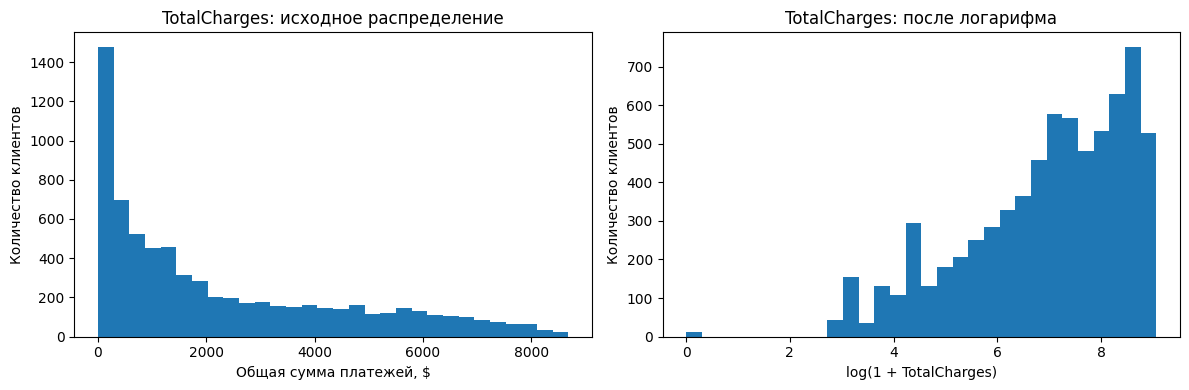

Решение: сохранить все наблюдения.
Размер таблицы: (7043, 21)


In [18]:
# решения: удалить, обрезать, логарифм

# Смотрим на распределение TotalCharges до и после логарифма
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["TotalCharges"], bins=30)
axes[0].set_title("TotalCharges: исходное распределение")
axes[0].set_xlabel("Общая сумма платежей, $")
axes[0].set_ylabel("Количество клиентов")

axes[1].hist(np.log1p(df["TotalCharges"]), bins=30)
axes[1].set_title("TotalCharges: после логарифма")
axes[1].set_xlabel("log(1 + TotalCharges)")
axes[1].set_ylabel("Количество клиентов")

plt.tight_layout()
plt.show()

# Не удаляем и не обрезаем значения без доказательства ошибки
print("Решение: сохранить все наблюдения.")
print("Размер таблицы:", df.shape)

log(
    "выбросы",
    "Проверены tenure, MonthlyCharges и TotalCharges методом IQR. "
    "Статистические выбросы не считаем ошибками без подтверждения. "
    "Строки не удалены, значения не обрезаны. "
    "Логарифм TotalCharges показан для сравнения распределений.",
    len(df)
)


**Вывод.** Я проверила три числовых столбца: tenure, MonthlyCharges и TotalCharges методом IQR.

По результатам проверки выбросов не обнаружено. Поэтому удалять строки или изменять значения не требуется.

Для TotalCharges я построила две гистограммы: с исходными значениями и после применения log1p. Это позволило сравнить распределения. При этом сами данные не изменялись.

После проверки осталось 7 043 строки и 21 столбец.

---
## 7. EDA: пять графиков  ·  20 баллов

**Что сделать.** Минимум 5 графиков. У каждого заголовок-вывод (не «lead_time и is_canceled», а «Чем раньше бронь, тем чаще отмена»), подписи осей с единицами и 1-3 предложения под графиком.

| график | на какой вопрос отвечает |
|---|---|
| распределение цели | какая доля классов или как распределено число |
| цель по 3-4 сильным признакам | что сильнее всего связано с целью |
| цель по времени или по группам | меняется ли картина по сезонам, городам, категориям |
| находка | что удивило: парадокс или подозрительно идеальный признак |

`target_plot(df, группы, TARGET, "заголовок-вывод", "подпись оси x")` рисует цель по группам. Числовой признак сначала разбейте на интервалы: `pd.cut(df["столбец"], [границы])`. Для двух числовых столбцов подойдёт `plt.scatter`.

Пример: часть 6 практики.

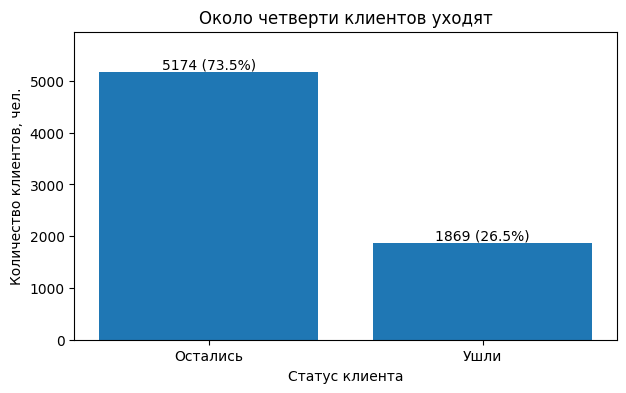

In [19]:
# график 1
# Считаем клиентов, которые остались и ушли
counts = df[TARGET].value_counts().sort_index()
percent = df[TARGET].value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(7, 4))
bars = plt.bar(["Остались", "Ушли"], counts.values)

for bar, n, p in zip(bars, counts.values, percent.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        f"{n} ({p:.1f}%)",
        ha="center"
    )

plt.title("Около четверти клиентов уходят")
plt.xlabel("Статус клиента")
plt.ylabel("Количество клиентов, чел.")
plt.ylim(0, counts.max() * 1.15)
plt.show()


**Что видно на графике 1.** Из 7 043 клиентов ушли 1 869 человек (26,5%), а 5 174 (73,5%) остались. Ушедших клиентов значительно меньше, чем оставшихся. Это важно учитывать при дальнейшем построении модели.

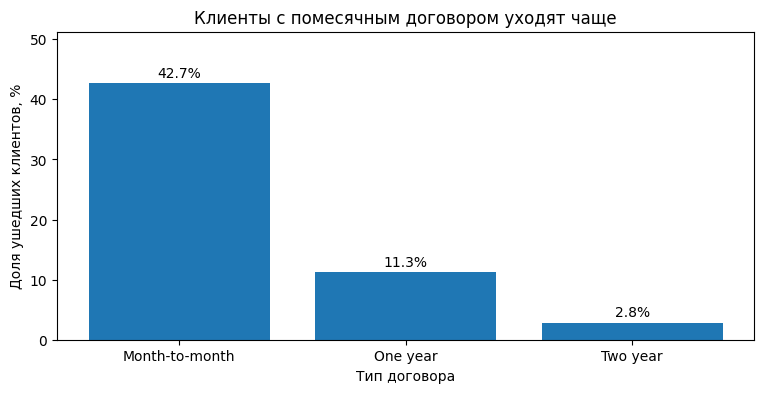

,Churn
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


In [20]:
# график 2

# Доля ушедших клиентов по типу договора
contract_churn = (
    df.groupby("Contract")[TARGET].mean() * 100
).sort_values(ascending=False)

plt.figure(figsize=(9, 4))
bars = plt.bar(contract_churn.index, contract_churn.values)

for bar, value in zip(bars, contract_churn.values):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 1,
             f"{value:.1f}%", ha="center")

plt.title("Клиенты с помесячным договором уходят чаще")
plt.xlabel("Тип договора")
plt.ylabel("Доля ушедших клиентов, %")
plt.ylim(0, max(contract_churn.max() * 1.2, 10))
plt.show()

display(contract_churn.round(2))


**Что видно на графике 2.** Самый высокий процент ухода наблюдается у клиентов с помесячным договором — 42,71%. При договоре на один год уходят 11,27%, а на два года — только 2,83%.

Таким образом, тип договора сильно связан с уходом клиентов. Однако это не означает, что именно договор является причиной ухода.

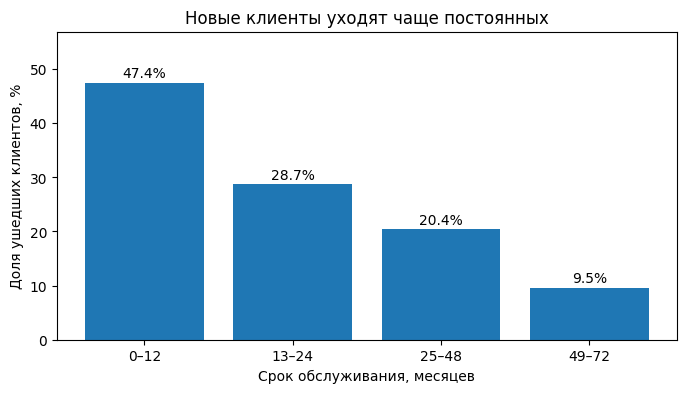

,Churn
tenure,
0–12,47.44
13–24,28.71
25–48,20.39
49–72,9.51


In [21]:
# график 3

# Делим клиентов на группы по сроку обслуживания
tenure_groups = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0–12", "13–24", "25–48", "49–72"]
)

tenure_churn = (
    df.groupby(tenure_groups, observed=True)[TARGET].mean() * 100
)

plt.figure(figsize=(8, 4))
bars = plt.bar(tenure_churn.index.astype(str),
               tenure_churn.values)

for bar, value in zip(bars, tenure_churn.values):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 1,
             f"{value:.1f}%", ha="center")

plt.title("Новые клиенты уходят чаще постоянных")
plt.xlabel("Срок обслуживания, месяцев")
plt.ylabel("Доля ушедших клиентов, %")
plt.ylim(0, max(tenure_churn.max() * 1.2, 10))
plt.show()

display(tenure_churn.round(2))


**Что видно на графике 3.** График показывает, как доля ушедших клиентов меняется в зависимости от срока обслуживания. Клиенты с небольшим сроком обслуживания чаще прекращают пользоваться услугами. Это говорит о том, что первые месяцы после подключения могут быть особенно важны для удержания клиентов.

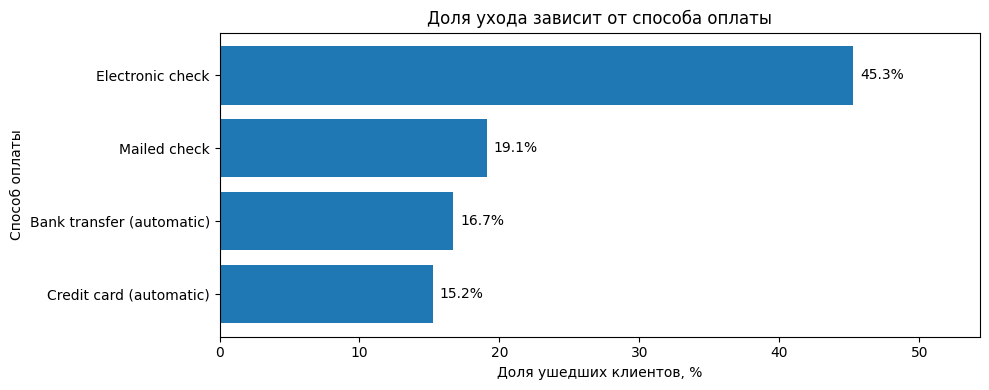

,Churn
PaymentMethod,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24


In [22]:
# график 4

# Сравниваем долю ушедших клиентов по способу оплаты
payment_churn = (
    df.groupby("PaymentMethod")[TARGET].mean() * 100
).sort_values(ascending=False)

plt.figure(figsize=(10, 4))
bars = plt.barh(payment_churn.index, payment_churn.values)

for bar, value in zip(bars, payment_churn.values):
    plt.text(value + 0.5,
             bar.get_y() + bar.get_height()/2,
             f"{value:.1f}%", va="center")

plt.title("Доля ухода зависит от способа оплаты")
plt.xlabel("Доля ушедших клиентов, %")
plt.ylabel("Способ оплаты")
plt.xlim(0, max(payment_churn.max() * 1.2, 10))
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

display(payment_churn.round(2))


**Что видно на графике 4.** На графике видно, что доля ушедших клиентов отличается в зависимости от способа оплаты. Особенно важно сравнить электронные чеки с автоматическими платежами. При этом способ оплаты может быть связан с другими особенностями клиентов, поэтому нельзя считать его доказанной причиной ухода.

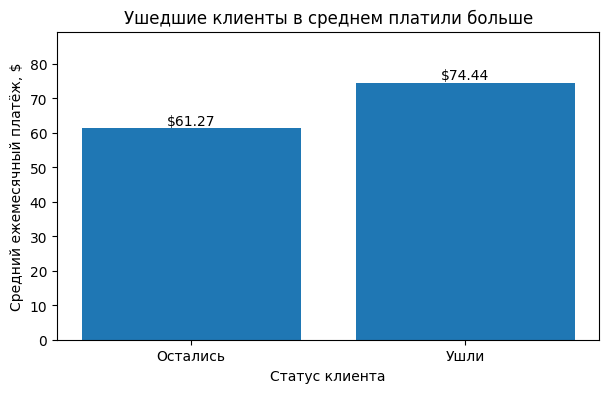

,MonthlyCharges
Churn,
0,61.27
1,74.44


In [23]:
# график 5

# Считаем средний платёж для двух групп клиентов
avg_payment = df.groupby(TARGET)["MonthlyCharges"].mean()

# Строим столбчатую диаграмму
plt.figure(figsize=(7, 4))
bars = plt.bar(
    ["Остались", "Ушли"],
    avg_payment.values
)

# Показываем суммы над столбцами
for bar, value in zip(bars, avg_payment.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"${value:.2f}",
        ha="center"
    )

plt.title("Ушедшие клиенты в среднем платили больше")
plt.xlabel("Статус клиента")
plt.ylabel("Средний ежемесячный платёж, $")
plt.ylim(0, avg_payment.max() * 1.2)
plt.show()

display(avg_payment.round(2))



**Что видно на графике 5.** На графике видно, что клиенты, которые ушли, в среднем платили больше за услуги связи, чем те, кто остался.

Это показывает, что размер ежемесячного платежа может быть связан с уходом клиентов. Однако нельзя утверждать, что именно высокая стоимость стала причиной ухода.

**Вывод по EDA.** В ходе анализа данных Telco Customer Churn я построила пять графиков и сделала следующие выводы:

Общий отток клиентов. Из 7 043 клиентов 26,5% прекратили пользоваться услугами компании, а 73,5% остались.

Тип договора. Клиенты с помесячным договором уходят чаще, чем клиенты с договорами на один или два года.

Срок обслуживания. Клиенты, которые пользуются услугами компании недавно, уходят чаще, чем постоянные клиенты.

Способ оплаты. Доля ушедших клиентов различается в зависимости от способа оплаты. Наиболее высокий отток наблюдается среди клиентов, использующих электронные чеки.

Ежемесячный платёж. Ушедшие клиенты в среднем платили больше за услуги, чем оставшиеся. Средний платёж ушедших составляет около 74,44 доллара, оставшихся — около 61,27 доллара.

Общий вывод: тип договора, срок обслуживания, способ оплаты и размер ежемесячного платежа связаны с уходом клиентов. Эти признаки стоит учитывать при дальнейшем анализе и построении модели прогнозирования оттока. При этом выявленные закономерности не доказывают, что именно эти факторы являются причинами ухода.

---
## 8. Функция clean, сторожа и журнал  ·  10 баллов

**Что сделать.**

* собрать все решения разделов 2-6 в одну функцию `clean(raw_table)`: на входе сырая таблица, на выходе чистая;
* проверить, что `clean(raw)` даёт ту же таблицу, что пошаговая очистка;
* сторожа: `assert` на главные правила, например «нет пропусков», «нет невозможных значений»;
* показать журнал: `show_journal()`;
* сохранить чистые данные: `clean_df.to_csv("data/<имя>_clean.csv", index=False)`.

Пример: часть 9 практики, разделы 9.1-9.4.

In [24]:
def clean(raw_table):
    """Очищает исходную таблицу Telco."""
    d = raw_table.copy()

    # Преобразуем Churn в 0 и 1, если он ещё текстовый
    if d[TARGET].dtype == "object":
        d[TARGET] = (d[TARGET] == "Yes").astype(int)

    # Удаляем полные дубли
    d = d.drop_duplicates().copy()

    # Находим пустые значения TotalCharges
    d["TotalCharges"] = d["TotalCharges"].replace(
        r"^\s*$", np.nan, regex=True
    )

    # Преобразуем TotalCharges в число
    d["TotalCharges"] = pd.to_numeric(
        d["TotalCharges"], errors="coerce"
    )

    # Проверяем причину пропусков
    missing = d["TotalCharges"].isna()
    assert (d.loc[missing, "tenure"] == 0).all()

    # Заполняем пропуски нулём
    d["TotalCharges"] = d["TotalCharges"].fillna(0)

    return d


In [25]:
# clean_df = clean(raw); сравнение с пошаговой очисткой; сторожа assert

# Запускаем очистку одной функцией
clean_df = clean(raw)

# Сравниваем с таблицей, очищенной пошагово
pd.testing.assert_frame_equal(
    clean_df.reset_index(drop=True),
    df.reset_index(drop=True)
)

# Проверяем качество данных
assert clean_df.isna().sum().sum() == 0
assert clean_df.duplicated().sum() == 0
assert clean_df["customerID"].is_unique
assert set(clean_df[TARGET].unique()) <= {0, 1}
assert not check_rules(clean_df).any().any()
assert pd.api.types.is_numeric_dtype(clean_df["TotalCharges"])

print("Все проверки пройдены: OK")
print("Размер чистой таблицы:", clean_df.shape)


Все проверки пройдены: OK
Размер чистой таблицы: (7043, 21)


In [26]:
# show_journal()

# Показываем журнал всех этапов очистки
display(show_journal())


,решение,строк
загрузка и цель,Telco: Churn преобразован из Yes/No в 1/0,7043
дубли,Удалены полные дубли: 0. Повторов customerID: 0,7043
невозможные значения,Подозрительных строк: 0. Скрытых пропусков Tot...,7043
пропуски,В TotalCharges найдено 11 пропусков. Все соотв...,7043
типы и даты,TotalCharges преобразован из текста в число. К...,7043
выбросы,"Проверены tenure, MonthlyCharges и TotalCharge...",7043


In [27]:
# Создаём папку для чистых данных
Path("data").mkdir(exist_ok=True)

# Сохраняем очищенную таблицу
clean_df.to_csv(
    "data/telco_clean.csv",
    index=False
)

print("Файл сохранён: data/telco_clean.csv")
print("Размер:", clean_df.shape)




Файл сохранён: data/telco_clean.csv
Размер: (7043, 21)


---
## 9. Самопроверка и репозиторий  ·  10 баллов

**Самопроверка.** Уберите `#` и запустите. Всё должно быть `OK`, а если где-то `НЕТ` по делу (например, дубли появились после обрезки выбросов, как в части 9 практики), объясните это в выводе.

In [28]:
# selfcheck(raw, clean_df, TARGET)

selfcheck(raw, clean_df, TARGET)

OK   цель есть в чистой таблице
OK   цель без пропусков
OK   цель числом: класс 0 и 1 или число
OK   в чистой таблице нет пропусков
OK   полных дублей нет (если есть, объясните в выводе)
OK   осталось больше половины строк
OK   в журнале минимум 5 решений
строк: было 7043, стало 7043; столбцов: было 21, стало 21


**Репозиторий.**

1. github.com, справа вверху «+», затем «New repository». Имя, например, `midterm-telco`, видимость **Public**, галочку README не ставить.
2. «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь проходит без ошибок. Сохраните её.
3. Скачайте тетрадь: «Файл», затем «Скачать», затем «Скачать .ipynb», имя `project.ipynb`. Скачайте чистый CSV из папки `data` на панели файлов слева.
4. На странице репозитория ссылка «uploading an existing file», перетащите `project.ipynb` и папку `data`, «Commit changes» с подписью «этап 1».
5. Откройте ссылку в режиме инкогнито: тетрадь открывается, графики видны. Сдайте ссылку в LMS.

README на этапе 1 можно сделать черновым: название проекта и одна строка о задаче. Полный README это этап 2.

Пример: часть 9 практики, разделы 9.5-9.6.

---
# Этап 2. Мидтерм, домашка занятия 12

Эти разделы заполняются после занятия 12, в этой же тетради и в том же репозитории. Здесь коротко, что в них будет. Подробности и баллы в ТЗ, примеры в частях 5, 7, 8 и 9 тетради практики занятия 11. Инструменты занятия 12 можно и нужно использовать.

## 10. Новые признаки

Минимум 3 признака из смысла задачи: суммы, доли, флаги, части дат. У каждого одно предложение «зачем». Пример: часть 5, раздел 5.1.

In [29]:
# этап 2

## 11. Категории

Редкие значения в `Other`, флаги через `get_dummies`. Итог: таблица признаков `X` только из чисел, без пропусков. Пример: часть 5, разделы 5.2-5.5.

In [30]:
# этап 2

## 12. Утечка

Таблица «столбец, когда становится известен, берём или нет» для всех подозрительных столбцов. Проверка моделью хотя бы одного подозреваемого: насколько он поднимает качество. Пример: часть 7.

In [31]:
# этап 2

## 13. Baseline

Train и test, пустышка, простая модель на 3-5 признаках, полная модель в `Pipeline`, кросс-валидация на train, test один раз в конце, график-лестница и вывод «модель лучше пустышки на ...». Пример: часть 8.

In [32]:
# этап 2

## 14. Выводы

3-5 пунктов: что узнали о данных, что сработало, что бы сделали дальше.

## 15. README

По шаблону из ТЗ. Журнал и результаты удобно собрать из переменных тетради. Пример: часть 9, раздел 9.4.

In [33]:
# этап 2

## 16. Финальная проверка

`requirements.txt`, «Перезапустить сеанс и выполнить все» без ошибок, тетрадь сохранена с выводами, ссылка открывается в режиме инкогнито. Чек-лист в ТЗ.